# Motion-crop bird detector (Keras → TFLite)

Notebook companion to `train_bird_detector_tflite.py`. The model consumes the Raspberry Pi's final motion crop, uses a 288×288 input and the MobileNetV2 `block_6_expand_relu` finder grid, expands each bird into neighbouring cells, and excludes legacy native 160×120 captures.

In [1]:
from pathlib import Path
import sys

def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'Models' / 'Multi_Object_Detector' / 'dataset_dirs.txt').is_file():
            return candidate
    raise FileNotFoundError('Could not find the project root')

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Models.Multi_Object_Detector import train_bird_detector_tflite as trainer
print('Project:', PROJECT_ROOT)
print('Default input:', trainer.DEFAULT_INPUT_SIZE)
print('Finder layer:', trainer.FEATURE_LAYER)
print('Max detections:', trainer.MAX_DETECTIONS)

Project: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier
Default input: 288
Finder layer: block_6_expand_relu
Max detections: 5


## Configuration

Set `SOURCE_RUN` to a run name or absolute path if you do not want the newest completed source run. Training is deliberately opt-in.

In [3]:
SOURCE_RUN = ''
INPUT_SIZE = 288  # 256, 288, or 320
BATCH_SIZE = 8
VERIFY_IMAGES = True
RUN_TRAINING = True

## Audit crop-only datasets

This excludes every native 160×120 capture and does not create full-scene evaluation rows.

In [4]:
audit_args = ['--audit-only', '--input-size', str(INPUT_SIZE)]
if SOURCE_RUN:
    audit_args += ['--source-run', SOURCE_RUN]
if VERIFY_IMAGES:
    audit_args.append('--verify-images')
trainer.main(audit_args)

         dataset  images  positive_images  negative_images  birds  missing_images
      train_crop   12677            10065             2612  11617               0
 validation_crop     506              373              133    500               0
       test_crop     147               80               67    112               0
calibration_crop     500              250              250    330               0


0

## Train, export, and evaluate

The training CSV logs `mean_positive_objectness` and `mean_negative_objectness`. Positive and negative focal losses are both normalized by the unique bird count. Set `RUN_TRAINING = True` above to run this cell.

In [5]:
if RUN_TRAINING:
    train_args = ['--input-size', str(INPUT_SIZE), '--batch-size', str(BATCH_SIZE)]
    if SOURCE_RUN:
        train_args += ['--source-run', SOURCE_RUN]
    if VERIFY_IMAGES:
        train_args.append('--verify-images')
    trainer.main(train_args)
else:
    print('Training skipped. Set RUN_TRAINING = True and rerun this cell.')

         dataset  images  positive_images  negative_images  birds  missing_images
      train_crop   12677            10065             2612  11617               0
 validation_crop     506              373              133    500               0
       test_crop     147               80               67    112               0
calibration_crop     500              250              250    330               0


I0000 00:00:1793048366.409154     561 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793048366.833729     561 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793048368.683500     561 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/train_bird_detector_tflite.py:561: UserWarning: 

Epoch 1/8


/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793048377.345051     854 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793048378.188781     762 service.cc:153] XLA service 0x763ea009bf10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793048378.188812     762 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6 (Driver: 13.4.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793048378.275361     762 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1

      4/Unknown 9s 38ms/step - loss: 832.4875 - mean_negative_objectness: 0.5090 - mean_positive_objectness: 0.5011

I0000 00:00:1793048384.159995     762 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


... (63 outputs left out)

INFO:tensorflow:Assets written to: /tmp/tmp6yfhtuf3/assets


Saved artifact at '/tmp/tmp6yfhtuf3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 288, 288, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 36, 36, 3, 5), dtype=tf.float32, name=None)
Captures:
  130016123943248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  130016123766160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  130016123765392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  130016123943824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  130016123944208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  130016123944016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  130016123767120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  130016123767888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  130016123767504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  130016123766736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1300161237

/home/joe/venvs/ESPclassifier/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793049084.460080     561 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793049084.460122     561 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793049084.460248     561 reader.cc:83] Reading SavedModel from: /tmp/tmp6yfhtuf3
I0000 00:00:1793049084.463369     561 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793049084.463394     561 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp6yfhtuf3
I0000 00:00:1793049084.495533     561 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793049084.689416     561 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp6yfhtuf3
I0000 00:00:1793049084.740434     561 loader.cc:471] SavedModel load for ta

Artifacts: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T012939Z/keras_motion_crop_detector
UINT8 TFLite: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T012939Z/exports/keras_motion_crop_detector/bird_detector_motion_crop_uint8.tflite
Decoder metadata: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Models/Multi_Object_Detector/runs/bird_detector_20261026T012939Z/exports/keras_motion_crop_detector/bird_detector_motion_crop_metadata.json


## Inspect training history

,epoch,learning_rate,loss,mean_negative_objectness,mean_positive_objectness,val_loss,val_mean_negative_objectness,val_mean_positive_objectness
26,18,0.000030,3.985344,0.025937,0.183324,3.983219,0.021960,0.108816
27,19,0.000030,3.981485,0.025916,0.183857,3.947033,0.025263,0.115410
28,20,0.000030,3.973767,0.025861,0.183942,3.933203,0.023061,0.113795
29,21,0.000009,3.972578,0.025698,0.184493,3.953305,0.024222,0.112628
30,22,0.000009,3.976212,0.025817,0.183989,3.961469,0.024236,0.112295


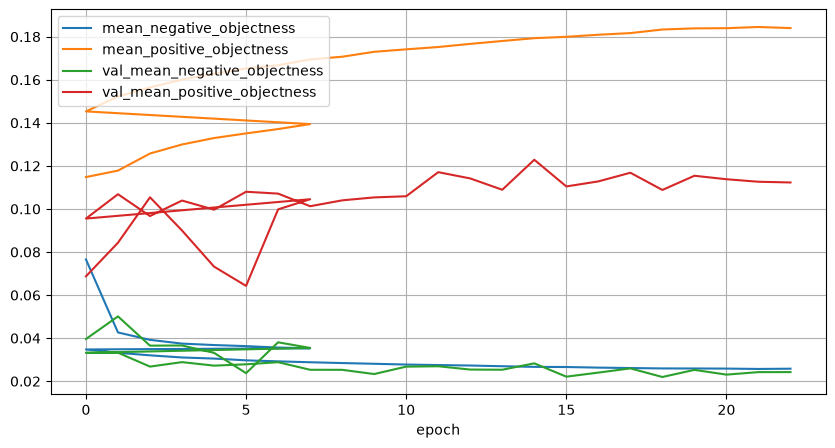

In [6]:
import pandas as pd

source_run = trainer.resolve_source_run(PROJECT_ROOT, SOURCE_RUN or None)
training_log = source_run / 'keras_motion_crop_detector' / 'training_log.csv'
if training_log.is_file():
    history = pd.read_csv(training_log)
    display(history.tail())
    score_columns = [column for column in history.columns if 'objectness' in column]
    if score_columns:
        history.plot(x='epoch', y=score_columns, grid=True, figsize=(10, 5))
else:
    print('No training log yet:', training_log)